# Reproduce Fig.1(b) data - LiveBench Part

In [ ]:
import numpy as np
import pandas as pd

B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [8]:
N_MATH_TRAIN = int(B_math.shape[0]/2)
N_CODING_TRAIN = int(B_coding.shape[0]/2)
N_REASONING_TRAIN = int(B_reasoning.shape[0]/2)
N_LANGUAGE_TRAIN = int(B_language.shape[0]/2)
print(N_MATH_TRAIN,N_CODING_TRAIN,N_REASONING_TRAIN,N_LANGUAGE_TRAIN)

184 64 75 70


In [15]:
B = pd.concat([B_language[:N_LANGUAGE_TRAIN], B_coding[:N_CODING_TRAIN], 
               B_reasoning[:N_REASONING_TRAIN], B_math[:N_MATH_TRAIN]],axis=0)

B_valid = pd.concat([B_language[N_LANGUAGE_TRAIN:], B_coding[N_CODING_TRAIN:], 
               B_reasoning[N_REASONING_TRAIN:], B_math[N_MATH_TRAIN:]],axis=0)

Y = pd.concat([Y_language[:N_LANGUAGE_TRAIN], Y_coding[:N_CODING_TRAIN], 
               Y_reasoning[:N_REASONING_TRAIN], Y_math[:N_MATH_TRAIN]],axis=0)

Y_valid = pd.concat([Y_language[N_LANGUAGE_TRAIN:], Y_coding[N_CODING_TRAIN:], 
               Y_reasoning[N_REASONING_TRAIN:], Y_math[N_MATH_TRAIN:]],axis=0)

c = pd.concat([c_language[:N_LANGUAGE_TRAIN], c_coding[:N_CODING_TRAIN], 
               c_reasoning[:N_REASONING_TRAIN], c_math[:N_MATH_TRAIN]])

c_valid = pd.concat([c_language[N_LANGUAGE_TRAIN:], c_coding[N_CODING_TRAIN:], 
               c_reasoning[N_REASONING_TRAIN:], c_math[N_MATH_TRAIN:]])


print(Y.shape, Y_valid.shape)
print(B.shape, B_valid.shape)
print(c.shape, c_valid.shape)

(393, 42) (393, 42)
(393, 42) (393, 42)
(393, 1) (393, 1)


In [16]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:10])

(393, 42) (393, 42)
0.3917653998177035 1308.0359869138495
(393,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02 1.e-02 1.e-05 1.e-02 1.e-05 1.e-05]


In [ ]:
Y_ij_valid= Y_valid.values.astype(float)
B_ij_valid = B_valid.values.astype(int)
c_i_valid = c_valid.values.squeeze()

print(Y_ij_valid.shape, B_ij_valid.shape)
print(Y_ij_valid.mean(), B_ij_valid.mean())
print(c_i_valid.shape, c_i_valid[:10])

(393, 42) (393, 42)
0.3954157918100872 1313.9521992002908
(393,) [1.e-05 1.e-05 1.e-02 1.e-05 1.e-05 1.e-05 1.e-02 1.e-05 1.e-05 1.e-02]


In [ ]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


In [21]:
x0_j = np.log1p(B_ij.mean(axis=0))

x0_j_valid = np.log1p(B_ij_valid.mean(axis=0))

# Evaluate with Reasoning-Aware 3PL's GEM

In [23]:
from reasoning_aware_irt.gem_quad import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem_quad import ReasoningAware3PLQuadraticCalibrator as ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)
cfg = CalibrationConfig()
cfg # lets see the default config


CalibrationConfig(gh_nodes=17, max_iter=50, tol=0.0001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=False, tau=0.75, ridge_a=0.001, ridge_b=0.001, ridge_gamma=0.1, ridge_kappa=0.1, mu_a=1.0, mu_b=0.0, mu_gamma=0.2, mu_kappa=-0.02, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-06, x0_j=None, ridge_x0=0.1)

In [24]:
## CONFIG
GH_NODES = 200
MAX_ITER = 200
MU_GAMMA = 0.002
MU_KAPPA = -0.005
KAPPA_MAX=-0.00001

OPTIMAL_KAPPA_INIT = True 

RIDGE_KAPPA = 1.0
RIDGE_GAMMA = 1.0
RIDGE_B = 0.1 # 0.05
RIDGE_A = 0.5
RIDGE_X0 = 1000

In [26]:
%%time
init_param_dict = None
    
cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j, optimal_kappa=OPTIMAL_KAPPA_INIT)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

fit_results = calibrator.fit(data, strict_Y_int=False, init_param_dict=init_param_dict)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=1.0, ridge_kappa=1.0, mu_a=1.0, mu_b=0.0, mu_gamma=0.002, mu_kappa=-0.005, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([6.31104187, 7.21863751, 6.25533971, 6.14395081, 6.02973673,
       6.31969682, 6.69598133, 5.96269589, 6.41680712, 6.13836436,
       5.78982788, 5.84672555, 5.86912439, 6.04258448, 5.90527171,
       5.78345714, 6.47526411, 6.2521882 , 6.71378754, 7.12078167,
       6.00492947, 6.66603697, 5.89249437, 5.81047798, 5.68682871,
       6.35526797, 5.71656724, 6.2692794 , 6.452727  , 6.5032096 ,
       6.52711683, 6.23988888, 5.96602277, 6.19354819, 8.0984046 ,
       7.77657665, 8.43560663, 8.84876175, 9.25183024, 8.83212762,
       7.11452531, 6.61509391]), ridge_x0=1000)


iter   1  ll=-7574.307636   dLL=nan
iter   2  ll=-7057.637139   dLL=nan
iter   3  ll=-7034.321628   dLL=2.332e+01
iter   4  ll=-7029.158465   dLL=5.163e+00
iter   5  ll=-7026.856070   dLL=2.302e+00
iter   6  ll=-7025.306401   dLL=1.550e+00
iter   7  ll=-7023.921437   dLL=1.385e+00
iter   8  ll=-7022.792014   dLL=1.129e+00
iter   9  ll=-7022.105471   dLL=6.865e-01
iter  10  ll=-7021.281720   dLL=8.238e-01
iter  11  ll=-7020.676308   dLL=6.054e-01
iter  12  ll=-7020.360139   dLL=3.162e-01
iter  13  ll=-7020.028272   dLL=3.319e-01
iter  14  ll=-7019.695952   dLL=3.323e-01
iter  15  ll=-7019.493153   dLL=2.028e-01
iter  16  ll=-7019.319185   dLL=1.740e-01
iter  17  ll=-7019.124428   dLL=1.948e-01
iter  18  ll=-7018.959373   dLL=1.651e-01
iter  19  ll=-7018.779981   dLL=1.794e-01
iter  20  ll=-7018.574213   dLL=2.058e-01
iter  21  ll=-7018.319463   dLL=2.547e-01
iter  22  ll=-7018.165831   dLL=1.536e-01
iter  23  ll=-7017.997983   dLL=1.678e-01
iter  24  ll=-7017.861446   dLL=1.365e-01
iter

In [27]:
fit_results.info['c_i'] = c_i

In [28]:
%%time
import joblib

data_valid = CalibrationData(Y_ij=Y_ij_valid, B_ij=B_ij_valid, c_i=c_i_valid)

init_param_dict = None
    
cfg = CalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_kappa=RIDGE_KAPPA, ridge_gamma=RIDGE_GAMMA, 
ridge_a=RIDGE_A, mu_gamma=MU_GAMMA, ridge_b=RIDGE_B,
mu_kappa=MU_KAPPA, kappa_max=KAPPA_MAX, tol=0.001,
ridge_x0=RIDGE_X0, x0_j=x0_j_valid, optimal_kappa=OPTIMAL_KAPPA_INIT)

calibrator = ReasoningAware3PLCalibrator(cfg)
print(cfg)

fit_results_valid = calibrator.fit(data_valid, strict_Y_int=False, init_param_dict=init_param_dict)

CalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, seed=0, verbose=True, use_quadratic=True, use_pin_posthoc=False, optimal_kappa=True, tau=0.75, ridge_a=0.5, ridge_b=0.1, ridge_gamma=1.0, ridge_kappa=1.0, mu_a=1.0, mu_b=0.0, mu_gamma=0.002, mu_kappa=-0.005, a_min=0.05, a_max=5.0, gamma_min=0.0, gamma_max=2.0, kappa_min=-2.0, kappa_max=-1e-05, x0_j=array([6.38757732, 7.14655577, 6.18749577, 6.0595155 , 6.12850124,
       6.31971057, 6.6389141 , 5.74217098, 6.34047149, 6.0592837 ,
       5.78548362, 5.83294152, 5.87252626, 6.04186495, 5.91311781,
       5.75632986, 6.31446955, 6.32192091, 6.58204276, 7.13444064,
       5.97085281, 6.57378678, 5.84270326, 5.8020415 , 5.66128924,
       6.31724276, 5.78182671, 6.18425906, 6.48524496, 6.41659091,
       6.52042999, 6.15825583, 5.94977412, 6.1484683 , 8.07471958,
       7.73804342, 8.39961414, 8.93232777, 9.27311326, 8.90215297,
       7.08098987, 6.60010934]), ridge_x0=1000)
iter   1  ll=-7491.982891   dLL=nan
iter   2  ll=-6903.5865

In [29]:
fit_results_valid.info['c_i'] = c_i_valid
print(fit_results.b_i.min(), fit_results.b_i.max())
print(fit_results_valid.b_i.min(), fit_results_valid.b_i.max())

-4.630179326404174 3.7000131771435214
-4.262446174994591 3.537374867272018


### Extract $p^{reason}_{ij}$, $p^{raw}_{ij}$ on held-out set

In [35]:
from reasoning_aware_irt.utils import compare_models, visualize_paired_losses, prob_correct_3pl
from sklearn.metrics import roc_auc_score

In [31]:
p_ij_simple = Y_ij.mean(axis=0) #Y_ij.astype(int).mean(axis=0)
p_ij_simple = np.tile(p_ij_simple, (Y_ij.shape[0],1))
print(p_ij_simple.shape)

(393, 42)


In [33]:
# item parameters from held-out set
a_i_valid = fit_results_valid.a_i
b_i_valid = fit_results_valid.b_i 
x_ij_valid = np.log1p(B_ij_valid)

# model parameters from training set
theta_j = fit_results.theta_j_mean
gamma_j = fit_results.gamma_j
kappa_j = fit_results.kappa_j


p_ij_valid = prob_correct_3pl(theta_j, a_i_valid, b_i_valid, c_i_valid, gamma_j, kappa_j, x_ij_valid)
print(p_ij_valid.shape, Y_ij_valid.shape)


(393, 42) (393, 42)


In [ ]:
# This is overall ROC-AUC. ROC-AUC by task, see below
print(roc_auc_score(Y_ij_valid.reshape(-1).astype(int) , p_ij_valid.reshape(-1)))
print(roc_auc_score(Y_ij_valid.reshape(-1).astype(int) , p_ij_simple.reshape(-1)))

0.8998814763073247
0.6760908527680665


## Evaluate Classic 3PL

In [43]:
from reasoning_aware_irt.classic_irt_em import IRT3PLCalibrator
from reasoning_aware_irt.classic_irt_em import ClassicCalibrationData, ClassicCalibrationConfig

In [45]:
%%time
# Train
data_classic = ClassicCalibrationData(Y_ij=Y_ij, c_i=c_i) # strict_Y_int already processed above

cfg_classic = ClassicCalibrationConfig(
gh_nodes=GH_NODES, max_iter=MAX_ITER, verbose=True,
ridge_a=RIDGE_A, ridge_b=RIDGE_B,tol=0.001)

calibrator_classic = IRT3PLCalibrator(cfg_classic)
print(cfg_classic)

classic_results = calibrator_classic.fit(data_classic)


ClassicCalibrationConfig(gh_nodes=200, max_iter=200, tol=0.001, a_min=0.05, a_max=None, ridge_a=0.5, ridge_b=0.1, verbose=True, random_state=None)
iter=  1  LL=-7204.102616  dLL=5.135e+02
iter=  2  LL=-7178.413452  dLL=2.569e+01
iter=  3  LL=-7166.380658  dLL=1.203e+01
iter=  4  LL=-7158.991998  dLL=7.389e+00
iter=  5  LL=-7154.246104  dLL=4.746e+00
iter=  6  LL=-7151.211638  dLL=3.034e+00
iter=  7  LL=-7148.969744  dLL=2.242e+00
iter=  8  LL=-7147.509645  dLL=1.460e+00
iter=  9  LL=-7146.481456  dLL=1.028e+00
iter= 10  LL=-7145.733552  dLL=7.479e-01
iter= 11  LL=-7145.176215  dLL=5.573e-01
iter= 12  LL=-7144.751988  dLL=4.242e-01
iter= 13  LL=-7144.422920  dLL=3.291e-01
iter= 14  LL=-7144.163419  dLL=2.595e-01
iter= 15  LL=-7143.954929  dLL=2.085e-01
iter= 16  LL=-7143.784760  dLL=1.702e-01
iter= 17  LL=-7143.643770  dLL=1.410e-01
iter= 18  LL=-7143.525017  dLL=1.188e-01
iter= 19  LL=-7143.423808  dLL=1.012e-01
iter= 20  LL=-7143.336537  dLL=8.727e-02
iter= 21  LL=-7143.260532  dLL=7.

In [46]:
%%time

data_classic_valid = ClassicCalibrationData(Y_ij=Y_ij_valid, c_i=c_i_valid)
classic_calibrator = IRT3PLCalibrator(cfg_classic)
classic_results_valid = classic_calibrator.fit(data_classic_valid)

iter=  1  LL=-7056.312773  dLL=5.655e+02
iter=  2  LL=-7029.391477  dLL=2.692e+01
iter=  3  LL=-7015.613352  dLL=1.378e+01
iter=  4  LL=-7007.554354  dLL=8.059e+00
iter=  5  LL=-7002.494666  dLL=5.060e+00
iter=  6  LL=-6999.213360  dLL=3.281e+00
iter=  7  LL=-6997.025995  dLL=2.187e+00
iter=  8  LL=-6995.513855  dLL=1.512e+00
iter=  9  LL=-6994.434823  dLL=1.079e+00
iter= 10  LL=-6993.645429  dLL=7.894e-01
iter= 11  LL=-6993.055686  dLL=5.897e-01
iter= 12  LL=-6992.606979  dLL=4.487e-01
iter= 13  LL=-6992.259513  dLL=3.475e-01
iter= 14  LL=-6991.986054  dLL=2.735e-01
iter= 15  LL=-6991.766819  dLL=2.192e-01
iter= 16  LL=-6991.588643  dLL=1.782e-01
iter= 17  LL=-6991.441257  dLL=1.474e-01
iter= 18  LL=-6991.317279  dLL=1.240e-01
iter= 19  LL=-6991.211736  dLL=1.055e-01
iter= 20  LL=-6991.120943  dLL=9.079e-02
iter= 21  LL=-6991.041530  dLL=7.941e-02
iter= 22  LL=-6990.971595  dLL=6.994e-02
iter= 23  LL=-6990.909381  dLL=6.221e-02
iter= 24  LL=-6990.853410  dLL=5.597e-02
iter= 25  LL=-69

### extract $p^{classic}_{ij}$ on held-out set

In [47]:

theta_j = classic_results.theta_j_mean # from train
a_i = classic_results_valid.a_i # from held-out
b_i = classic_results_valid.b_i # from held-out

p_ij_classic = prob_correct_3pl(theta_j, a_i, b_i, c_i)
print(p_ij_classic.shape, Y_ij_valid.shape)

print(roc_auc_score(Y_ij_valid.reshape(-1).astype(int) , p_ij_classic.reshape(-1)))
print(roc_auc_score(Y_ij_valid.reshape(-1).astype(int) , p_ij_simple.reshape(-1)))

(393, 42) (393, 42)
0.8845513078634369
0.6760908527680665


# ROC-AUC by Tasks for all methods

In [40]:
problem_type_np = np.array(['lang']*N_LANGUAGE_TRAIN + ['code']*N_CODING_TRAIN + ['reason']*N_REASONING_TRAIN + ['math']*N_MATH_TRAIN )

In [48]:
IDS = [N_LANGUAGE_TRAIN, 
       N_CODING_TRAIN, 
       N_REASONING_TRAIN, 
       N_MATH_TRAIN]

our_roc_list = []
classic_roc_list = []
simple_roc_list = []

roc_problem_category_list = []

cum_ids=0
for ii, ids in enumerate(IDS):

    roc_problem_category_list.append(problem_type_np[cum_ids + ids-1])#.upper()
    our_roc_list.append(roc_auc_score(Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1) , p_ij_valid[cum_ids:cum_ids+ids,:].reshape(-1)))
    simple_roc_list.append(roc_auc_score(Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1) , p_ij_simple[cum_ids:cum_ids+ids,:].reshape(-1) ))
    classic_roc_list.append(roc_auc_score(Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1) , p_ij_classic[cum_ids:cum_ids+ids,:].reshape(-1) ))

    print(f'\n{ii+1} - {roc_problem_category_list[-1]} - cum_ids:{cum_ids} - ids:{ids}')
    print(f'reasoning-aware: {our_roc_list[-1]:.3f}')
    print(f'classic-score: {classic_roc_list[-1]:.3f}')
    print(f'simple-score: {simple_roc_list[-1]:.3f}')
    cum_ids += ids


1 - lang - cum_ids:0 - ids:70
reasoning-aware: 0.876
classic-score: 0.877
simple-score: 0.657

2 - code - cum_ids:70 - ids:64
reasoning-aware: 0.946
classic-score: 0.946
simple-score: 0.628

3 - reason - cum_ids:134 - ids:75
reasoning-aware: 0.842
classic-score: 0.831
simple-score: 0.689

4 - math - cum_ids:209 - ids:184
reasoning-aware: 0.908
classic-score: 0.879
simple-score: 0.700


In [49]:
from reasoning_aware_irt.utils import plot_dumbbell

In [50]:
c = ['Simple Accuracy', 'Classic 3PL', 'Ours', ]

data_roc_plot_list =[]
for i in range(len(our_roc_list)):
    # adhoc to optimize c-rendering
    cat = c if i % 3 == 0 else [' ', '  ', '   '] # need unique name
    data_roc_plot_list.append({
            'categories': cat,
            'bg': [simple_roc_list[i], classic_roc_list[i], our_roc_list[i]],
            'fg': [0, 0, our_roc_list[i]],
            'title': roc_problem_category_list[i],
            'x_label':'',
            'color':'g'}
            )

save fig to Fig1_right.pdf ... success!


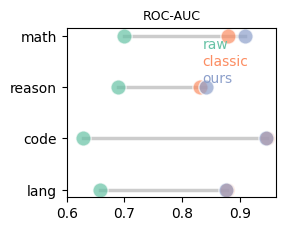

In [ ]:
plot_dumbbell(ax=None, datasets=data_roc_plot_list, categories=cat, x_label="",
              x_ticks=[0.6,0.7,0.8, 0.9],
              nickname=['raw', 'classic', 'ours'], x_nickname=0.65, y_nickname=0.88,
              title='ROC-AUC', plot_legend=False, figsize=(2.7, 2.2),save_path="Fig1_right_partial.pdf")

## Statistical Significance (Part of Appendix D.4)

In [53]:
from reasoning_aware_irt.utils import compare_models

In [54]:
## reasoning-aware vs. raw : paired-t and binomial sign tests
cum_ids=0
for ii, ids in enumerate(IDS):
    print(f'\n{ii+1} - {roc_problem_category_list[-1]} - cum_ids:{cum_ids} - ids:{ids}')
    compare_models(p_ij_valid[cum_ids:cum_ids+ids,:].reshape(-1), p_ij_simple[cum_ids:cum_ids+ids,:].reshape(-1), 
                   Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1), 
                   metric='cross-entropy', test='paired-t', alternative='less')
    print()
    compare_models(p_ij_valid[cum_ids:cum_ids+ids,:].reshape(-1), p_ij_simple[cum_ids:cum_ids+ids,:].reshape(-1), 
                   Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1), 
                   metric='cross-entropy', test='binomtest', alternative='less')
    print()
    
    cum_ids += ids


1 - math - cum_ids:0 - ids:70
--- Model Comparison Report ---
Metric Used : Log Loss (Cross-Entropy)
Test Used   : Paired t-test (alternative='less')
Model 1 Mean Loss : 0.4072
Model 2 Mean Loss : 0.5829
Model 1 Win Rate  : 78.2% of individual predictions

Test Statistic : -26.3847
p-value        : 3.6002e-138

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because its loss is significantly lower.

--- Model Comparison Report ---
Metric Used : Log Loss (Cross-Entropy)
Test Used   : Sign Test (Binomial) (alternative='less')
Model 1 Mean Loss : 0.4072
Model 2 Mean Loss : 0.5829
Model 1 Win Rate  : 78.2% of individual predictions

Test Statistic : 2300.0000
p-value        : 2.3782e-218

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because it wins significantly more often.


2 - math - cum_ids:70 - ids:64
--- Model Comparison Report ---
Metric Used : Log Loss (Cross-

In [55]:
## classic 3PL vs. raw : paired-t and binomial sign tests
cum_ids=0
for ii, ids in enumerate(IDS):
    print(f'\n{ii+1} - {roc_problem_category_list[-1]} - cum_ids:{cum_ids} - ids:{ids}')
    compare_models(p_ij_classic[cum_ids:cum_ids+ids,:].reshape(-1), p_ij_simple[cum_ids:cum_ids+ids,:].reshape(-1), 
                   Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1), 
                   # metric='square error', test='wilcoxon', alternative='less')
                   metric='cross-entropy', test='paired-t', alternative='less')
    print()
    compare_models(p_ij_classic[cum_ids:cum_ids+ids,:].reshape(-1), p_ij_simple[cum_ids:cum_ids+ids,:].reshape(-1), 
                   Y_ij_valid[cum_ids:cum_ids+ids,:].astype(int).reshape(-1), 
                   # metric='square error', test='wilcoxon', alternative='less')
                   metric='cross-entropy', test='binomtest', alternative='less')
    print()
    
    cum_ids += ids


1 - math - cum_ids:0 - ids:70
--- Model Comparison Report ---
Metric Used : Log Loss (Cross-Entropy)
Test Used   : Paired t-test (alternative='less')
Model 1 Mean Loss : 0.4070
Model 2 Mean Loss : 0.5829
Model 1 Win Rate  : 77.5% of individual predictions

Test Statistic : -26.3106
p-value        : 1.7518e-137

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because its loss is significantly lower.

--- Model Comparison Report ---
Metric Used : Log Loss (Cross-Entropy)
Test Used   : Sign Test (Binomial) (alternative='less')
Model 1 Mean Loss : 0.4070
Model 2 Mean Loss : 0.5829
Model 1 Win Rate  : 77.5% of individual predictions

Test Statistic : 2278.0000
p-value        : 2.4678e-206

✅ CONCLUSION: Model 1 is significantly BETTER than Model 2.
   At alpha=0.05, we reject the null hypothesis because it wins significantly more often.


2 - math - cum_ids:70 - ids:64
--- Model Comparison Report ---
Metric Used : Log Loss (Cross-